Analisando o gráfico das correntes verifica-se que o problema inicia-se um pouco antes dos 600 ms.

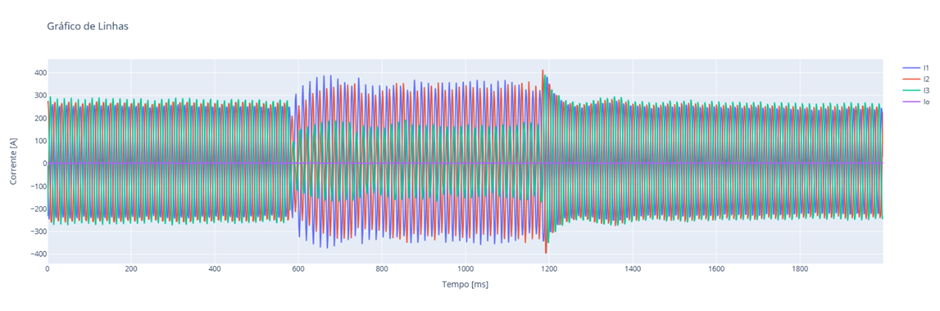

Aplicando-se um zoom entre 570 e 650 ms se verifica uma mudança extrema na fase da corrente da fase 3, o que sugere uma entrada errada de um bloco capacitivo.


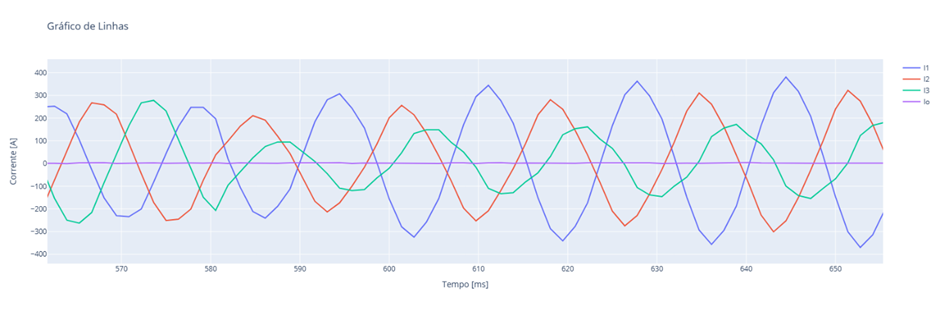


* Focando na tensão junto com a corrente desta mesma fase 3 observa-se:
Veja que a corrente de atrasada passou a muito adiantada adiantada (fortemente capacitiva).

* Na fase 1 a corrente fica praticamente em fase, contudo também levemente adiantada:

* Na fase 2 a fase ao invés de adiantar a corrente, como o previsto, ela inclusive se atrasa com relação à tensão.

In [27]:
import pandas as pd

# Substitua 'seu_arquivo.xlsx' pelo caminho do seu arquivo Excel
caminho_do_arquivo = 'Oscilografia cbc.xlsm'

# Lê o arquivo Excel e o salva em um DataFrame
df = pd.read_excel(caminho_do_arquivo, sheet_name=2)

# Mostra as primeiras linhas do DataFrame para verificação
df


,t,I1,I2,I3,Io,V1,V2,V3
0,0.00000,-6.38175,264.64600,-232.5350,1.850850,-3116.57,10524.70,-7789.49
1,1.38889,-127.63500,275.59600,-120.3710,3.238980,-7917.42,10529.00,-1742.42
2,2.77778,-223.36100,232.70600,15.5023,0.462711,-10195.50,7784.21,3397.94
3,4.16667,-246.15300,124.11000,146.8160,1.388130,-10259.20,1973.20,8271.80
4,5.55556,-217.89100,-19.16400,261.7160,0.462711,-7688.60,-3145.82,10579.10
...,...,...,...,...,...,...,...,...
1435,1993.06000,213.33300,-223.58000,34.6523,1.850850,10544.50,-8487.78,-2809.89
1436,1994.44000,244.33000,-131.41000,-84.8069,2.776270,10644.40,-2836.02,-7832.94
1437,1995.83000,230.65500,-1.82514,-205.1780,1.388130,8482.23,2634.79,-10834.00
1438,1997.22000,154.07400,116.80900,-245.3020,2.313560,2861.68,7646.68,-10935.40


In [14]:
import plotly.graph_objects as go

# Supondo que 'df' é o seu DataFrame
x = df.iloc[:, 0]  # Primeira coluna para o eixo X
y_columns = df.columns[1:5]  # Colunas de dados para o eixo Y

fig = go.Figure()

for col in y_columns:
    fig.add_trace(go.Scatter(x=x, y=df[col], mode='lines', name=col))

fig.update_layout(title='Gráfico de Linhas', xaxis_title='Tempo [ms]', yaxis_title='Corrente [A]')
fig.show()


In [15]:
y_columns = df.columns[5:8]  # Colunas de dados para o eixo Y

fig = go.Figure()

for col in y_columns:
    fig.add_trace(go.Scatter(x=x, y=df[col], mode='lines', name=col))

fig.update_layout(title='Gráfico de Linhas', xaxis_title='Tempo [ms]', yaxis_title='Tensões [V]')
fig.show()

In [16]:
fig = go.Figure()

# Adiciona a primeira linha no eixo Y primário
fig.add_trace(go.Scatter(x=x, y=df.iloc[:, 1], mode='lines', name=df.columns[1], line=dict(width=2)))

# Adiciona a segunda linha no eixo Y secundário
fig.add_trace(go.Scatter(x=x, y=df.iloc[:, 5], mode='lines', name=df.columns[5], yaxis='y2', line=dict(width=0.5)))

# Atualiza o layout para incluir o eixo Y secundário
fig.update_layout(
    title='Fase 1',
    xaxis_title='Tempo [ms]',
    yaxis=dict(title='Corrente'),
    yaxis2=dict(title='Tensão', overlaying='y', side='right')
)

fig.show()



In [17]:
fig = go.Figure()

# Adiciona a primeira linha no eixo Y primário
fig.add_trace(go.Scatter(x=x, y=df.iloc[:, 2], mode='lines', name=df.columns[2], line=dict(width=2)))

# Adiciona a segunda linha no eixo Y secundário
fig.add_trace(go.Scatter(x=x, y=df.iloc[:, 6], mode='lines', name=df.columns[6], yaxis='y2', line=dict(width=0.5)))

# Atualiza o layout para incluir o eixo Y secundário
fig.update_layout(
    title='Fase 2',
    xaxis_title='Tempo [ms]',
    yaxis=dict(title='Corrente'),
    yaxis2=dict(title='Tensão', overlaying='y', side='right')
)

fig.show()

In [18]:
fig = go.Figure()

# Adiciona a primeira linha no eixo Y primário
fig.add_trace(go.Scatter(x=x, y=df.iloc[:, 3], mode='lines', name=df.columns[3], line=dict(width=2)))

# Adiciona a segunda linha no eixo Y secundário
fig.add_trace(go.Scatter(x=x, y=df.iloc[:, 7], mode='lines', name=df.columns[7], yaxis='y2', line=dict(width=0.5)))

# Atualiza o layout para incluir o eixo Y secundário
fig.update_layout(
    title='Fase 3',
    xaxis_title='Tempo [ms]',
    yaxis=dict(title='Corrente'),
    yaxis2=dict(title='Tensão', overlaying='y', side='right')
)

fig.show()

In [32]:
fig = go.Figure()

# Adiciona a primeira linha no eixo Y primário
fig.add_trace(go.Scatter(x=x, y=df.iloc[:, 1], mode='lines', name=df.columns[1], line=dict(width=1)))
fig.add_trace(go.Scatter(x=x, y=df.iloc[:, 2], mode='lines', name=df.columns[2], line=dict(width=1)))
fig.add_trace(go.Scatter(x=x, y=df.iloc[:, 3], mode='lines', name=df.columns[3], line=dict(width=1)))


# Adiciona a segunda linha no eixo Y secundário
fig.add_trace(go.Scatter(x=x, y=df.iloc[:, 5], mode='lines', name=df.columns[5], yaxis='y2', line=dict(width=1, dash='dot')))
fig.add_trace(go.Scatter(x=x, y=df.iloc[:, 6], mode='lines', name=df.columns[6], yaxis='y2', line=dict(width=1, dash='dot')))
fig.add_trace(go.Scatter(x=x, y=df.iloc[:, 7], mode='lines', name=df.columns[7], yaxis='y2', line=dict(width=1, dash='dot')))

# Atualiza o layout para incluir o eixo Y secundário
fig.update_layout(
    title='Tensões e Correntes',
    xaxis_title='Tempo [ms]',
    yaxis=dict(title='Corrente'),
    yaxis2=dict(title='Tensão', overlaying='y', side='right')
)

fig.show()
fig.write_html('grafico.html')
from google.colab import files
files.download('grafico.html')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
fig = go.Figure()

# Adiciona a primeira linha no eixo Y primário
fig.add_trace(go.Scatter(x=x, y=df.iloc[:, 4], mode='lines', name=df.columns[4], line=dict(width=2)))



# Atualiza o layout para incluir o eixo Y secundário
fig.update_layout(
    title='Corrente de Neutro',
    xaxis_title='Tempo [ms]',
    yaxis=dict(title='Corrente'),
)

fig.show()

In [21]:
import numpy as np
from scipy.fft import fft, fftfreq
tempo = np.array(df.iloc[:, 0])
corrente_de_neutro = np.array(df.iloc[:, 4])
corrente_fase_a = np.array(df.iloc[:, 1])
corrente_fase_b = np.array(df.iloc[:, 2])
corrente_fase_c = np.array(df.iloc[:, 3])
N = len(tempo)
T = tempo[1] - tempo[0]
fft_corrente_de_neutro = fft(corrente_de_neutro)
fft_corrente_fase_a = fft(corrente_fase_a)
fft_corrente_fase_b = fft(corrente_fase_b)
fft_corrente_fase_c = fft(corrente_fase_c)
frequencias = fftfreq(N, T)[:N//2]
magnitude_corrente_de_neutro = 2.0/N * np.abs(fft_corrente_de_neutro[0:N//2])
magnitude_corrente_de_neutro[0] = magnitude_corrente_de_neutro[0] / 2
magnitude_corrente_fase_a = 2.0/N * np.abs(corrente_fase_a[0:N//2])
magnitude_corrente_fase_b = 2.0/N * np.abs(corrente_fase_b[0:N//2])
magnitude_corrente_fase_c = 2.0/N * np.abs(corrente_fase_c[0:N//2])

In [22]:
fig = go.Figure()

# Adicionando as magnitudes de cada corrente ao gráfico
fig.add_trace(go.Scatter(x=frequencias, y=magnitude_corrente_de_neutro, mode='lines', name='Corrente de Neutro'))
fig.add_trace(go.Scatter(x=frequencias, y=magnitude_corrente_fase_a, mode='lines', name='Corrente Fase A'))
fig.add_trace(go.Scatter(x=frequencias, y=magnitude_corrente_fase_b, mode='lines', name='Corrente Fase B'))
fig.add_trace(go.Scatter(x=frequencias, y=magnitude_corrente_fase_c, mode='lines', name='Corrente Fase C'))

fig.update_layout(
    title='Espectro de Harmônicos das Correntes',
    xaxis_title='Frequência (Hz)',
    yaxis_title='Magnitude',
    template='plotly_white'
)

fig.show()


In [23]:
import numpy as np
from scipy.fft import fft, fftfreq
tempo = np.array(df.iloc[:, 0])
tensao_fase_a = np.array(df.iloc[:, 5])
tensao_fase_b = np.array(df.iloc[:, 6])
tensao_fase_c = np.array(df.iloc[:, 7])

tensao_deslocamento_neutro = (tensao_fase_a + tensao_fase_b + tensao_fase_c) / 3

tensao_linha_ab = tensao_fase_a - tensao_fase_b
tensao_linha_bc = tensao_fase_b - tensao_fase_c
tensao_linha_ca = tensao_fase_c - tensao_fase_a

In [24]:
fig = go.Figure()

# Adicionando as tensões de fase ao gráfico
fig.add_trace(go.Scatter(x=tempo, y=tensao_fase_a, mode='lines', name='Tensão Fase A'))
fig.add_trace(go.Scatter(x=tempo, y=tensao_fase_b, mode='lines', name='Tensão Fase B'))
fig.add_trace(go.Scatter(x=tempo, y=tensao_fase_c, mode='lines', name='Tensão Fase C'))

# Adicionando a tensão de deslocamento de neutro ao gráfico
fig.add_trace(go.Scatter(x=tempo, y=tensao_deslocamento_neutro, mode='lines', name='Tensão de Deslocamento de Neutro'))

fig.update_layout(
    title='Tensões de Fase e Tensão de Deslocamento de Neutro',
    xaxis_title='Tempo',
    yaxis_title='Tensão',
    template='plotly_white'
)

fig.show()


In [25]:
fig = go.Figure()

# Adicionando as tensões de linha ao gráfico
fig.add_trace(go.Scatter(x=tempo, y=tensao_linha_ab, mode='lines', name='Tensão Linha AB'))
fig.add_trace(go.Scatter(x=tempo, y=tensao_linha_bc, mode='lines', name='Tensão Linha BC'))
fig.add_trace(go.Scatter(x=tempo, y=tensao_linha_ca, mode='lines', name='Tensão Linha CA'))


fig.update_layout(
    title='Tensões de Linha e Verificação de Soma Zero',
    xaxis_title='Tempo',
    yaxis_title='Tensão',
    template='plotly_white'
)

fig.show()


In [26]:
df

,t,I1,I2,I3,Io,V1,V2,V3
0,0.00000,-6.38175,264.64600,-232.5350,1.850850,-3116.57,10524.70,-7789.49
1,1.38889,-127.63500,275.59600,-120.3710,3.238980,-7917.42,10529.00,-1742.42
2,2.77778,-223.36100,232.70600,15.5023,0.462711,-10195.50,7784.21,3397.94
3,4.16667,-246.15300,124.11000,146.8160,1.388130,-10259.20,1973.20,8271.80
4,5.55556,-217.89100,-19.16400,261.7160,0.462711,-7688.60,-3145.82,10579.10
...,...,...,...,...,...,...,...,...
1435,1993.06000,213.33300,-223.58000,34.6523,1.850850,10544.50,-8487.78,-2809.89
1436,1994.44000,244.33000,-131.41000,-84.8069,2.776270,10644.40,-2836.02,-7832.94
1437,1995.83000,230.65500,-1.82514,-205.1780,1.388130,8482.23,2634.79,-10834.00
1438,1997.22000,154.07400,116.80900,-245.3020,2.313560,2861.68,7646.68,-10935.40
